# Введение в статистику

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

## 1
1. Продукт считает, что среднее время на карточке вакансии равно 120 секунд.
Собрали n = 100 пользователей, ¯x = 124 секунды. Разброс одного наблюдения в
генеральной совокупности известен заранее: σ = 25 секунд. Сформулируйте H0.
Посчитайте, на сколько стандартных ошибок оценка ушла от 120. Решите, есть
ли основание отвергать H0

In [2]:
def _():
    """
    За H0 берем то, что реальное среднее время на карточке вакансии равно 120 секундам.
    """

    t_mean = 120

    # выборочная совокупность
    n = 100
    x_mean = 124
    # генеральная совокупность
    sig = 25

    # считаем z статистику
    z = (x_mean - t_mean) / (sig / np.sqrt(n))
    
    p_value = 2 * stats.norm.sf(abs(z))

    print(f"z-статистика: {z}")
    print(f"p-value: {p_value:.3f}")


_()

z-статистика: 1.6
p-value: 0.110


Нулевая гипотеза H0: истинное среднее время на карточке вакансии равно 120 секундам. Выборочное среднее ушло от 120 на 1.6 стандартной ошибки (z = 1.6). Полученное p-value равно 0.110, что больше уровня значимости 0.05, поэтому оснований отвергать H0 нет.

## 2
2. Первая группа: n1 = 40, ¯x1 = 50, выборочное среднеквадратическое отклонение
s1 = 10. Вторая группа: n2 = 40, ¯x2 = 55, s2 = 10. Генеральные разбросы двух групп
неизвестны и равными их считать не нужно. Посчитайте разницу средних и
95% доверительный интервал для нее. Напишите, попадает ли 0 в интервал и
какой самый маленький эффект еще согласуется с данными (который не будет
опровергать H0).

In [13]:
def _():
    # вводные данные
    n1, x1_mean, s1 = 40, 50, 10
    n2, x2_mean, s2 = 40, 55, 10

    # разница средних
    diff_mean = x2_mean - x1_mean

    # Welch t-test
    se = np.sqrt(s1**2 / n1 + s2**2 / n2)

    df = (s1**2 / n1 + s2**2 / n2)**2 / ((s1**2 / n1)**2 / (n1 - 1) + (s2**2 / n2)**2 / (n2 - 1))

    # квантиль t-распределения для 95% ДИ (двусторонний, поэтому 0.975)
    t_val = stats.t.ppf(0.975, df)

    # границы доверительного интервала
    i_low = diff_mean - t_val * se
    i_high = diff_mean + t_val * se

    print(f"Разница средних: {diff_mean}")
    print(f"95% ДИ: от {i_low:.3f} до {i_high:.3f}")


_()

Разница средних: 5
95% ДИ: от 0.548 до 9.452


Разница средних получилась равна 5, а 95% доверительный интервал для нее от 0.548 до 9.452. Ноль в этот интервал не попадает, значит разница между группами статистически значима и H0 можно отвергнуть. Самый маленький эффект, который еще согласуется с данными, равен нижней границе интервала, то есть 0.548.

## 3
3. Первая группа: 90 откликов на 1000 показов карточки. Вторая группа: 120
откликов на 1000 показов. Каждый показ относится к своему пользователю,
20
группы независимы. Сформулируйте H0 про две конверсии. Посчитайте
разницу в процентных пунктах и статистику критерия для двух долей. Решите,
есть ли основание отвергать H0.
Как набирать выборки в задачах 4–7. Используйте генератор случайных чисел
из numpy: сначала rng = np.random.default_rng(7), потом rng.normal(mu, sigma,
size). Здесь mu — среднее, sigma — разброс одного наблюдения, size — сколько
наблюдений набрать. Так же записывается N (μ, σ): первое число — среднее,
второе — разброс одного наблюдения. Число в скобках после default_rng —
стартовое число генератора. При одном и том же числе выборки каждый раз
получаются одинаковыми, поэтому результат можно повторить. Возьмите любое
число и напишите, какое взяли

In [15]:
def _():
    """
    За H0 берем то, что конверсии в обеих группах одинаковые (разницы между ними нет).
    """

    # вводные данные
    x1, n1 = 90, 1000
    x2, n2 = 120, 1000

    # считаем конверсии
    p1 = x1 / n1
    p2 = x2 / n2

    # разница в процентных пунктах
    diff_pp = (p2 - p1) * 100

    # общая доля для двух групп
    p = (x1 + x2) / (n1 + n2)

    # считаем z-статистику для двух долей
    z = (p2 - p1) / np.sqrt(p * (1 - p) * (1 / n2 + 1 / n1))

    p_value = 2 * stats.norm.sf(abs(z))

    print(f"Разница конверсий: {diff_pp:.1f} п.п.")
    print(f"z-статистика: {z:.3f}")
    print(f"p-value: {p_value:.3f}")


_()

Разница конверсий: 3.0 п.п.
z-статистика: 2.188
p-value: 0.029


Нулевая гипотеза H0: конверсии в обеих группах одинаковые (разницы между ними нет). Конверсия во второй группе выше на 3 п. п. (12% против 9%), а z-статистика для двух долей равна 2.188. Полученное p-value меньше уровня значимости 0.05, поэтому основание отвергать H0 есть.

## 4
4. Повторите эксперимент 2000 раз. В каждом повторе заново наберите две
группы по n = 200 наблюдений из одного и того же N (0, 1). На каждой паре
групп посчитайте t Уэлча и его p-value. Нарисуйте распределение p-value.
Напишите, какую форму оно имеет и почему.

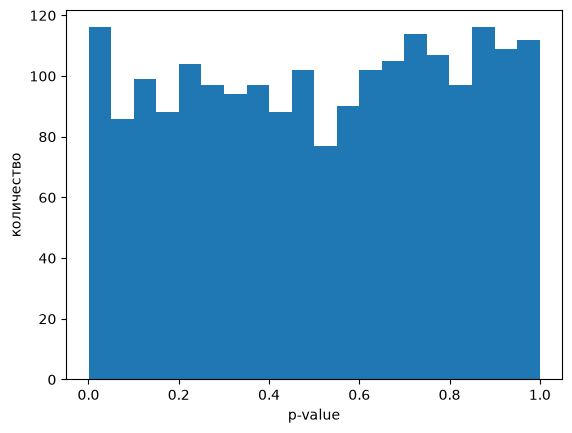

In [16]:
def _():
    rng = np.random.default_rng(7)

    p_vals = []

    for _ in range(2000):
        g1 = rng.normal(0, 1, 200)
        g2 = rng.normal(0, 1, 200)
        
        res = stats.ttest_ind(g1, g2, equal_var=False)
        p_vals.append(res.pvalue)

    plt.hist(p_vals, bins=20)
    plt.xlabel("p-value")
    plt.ylabel("количество")
    plt.show()

_()

Для генератора взял стартовое число 7. Распределение p-value на гистограмме получилось плоским и близким к равномерному на отрезке от 0 до 1. Так вышло потому, что обе группы генерируются из одного и того же распределения N(0, 1), то есть реальной разницы между ними нет и нулевая гипотеза H0 верна. Когда H0 верна, любое значение p-value от 0 до 1 выпадает с одинаковой вероятностью.

## 5
5. Повторите эксперимент 1000 раз. Первая группа каждый раз из N (0, 1), n = 60.
Вторая из N (1, 1), тоже n = 60; после этого два ее наблюдения замените на −50.
На каждой паре групп посчитайте разницу средних, t Уэлча, U Манна–Уитни
для первой группы и p-value обоих критериев. Нарисуйте распределения t и
U . Нарисуйте распределения p-value обоих критериев и отметьте на них 0,05.
Сравните, где они сосредоточены. Какое решение при двустороннем пороге
5% принимает каждый критерий? Совпали выводы или разошлись? Объясните,
почему.

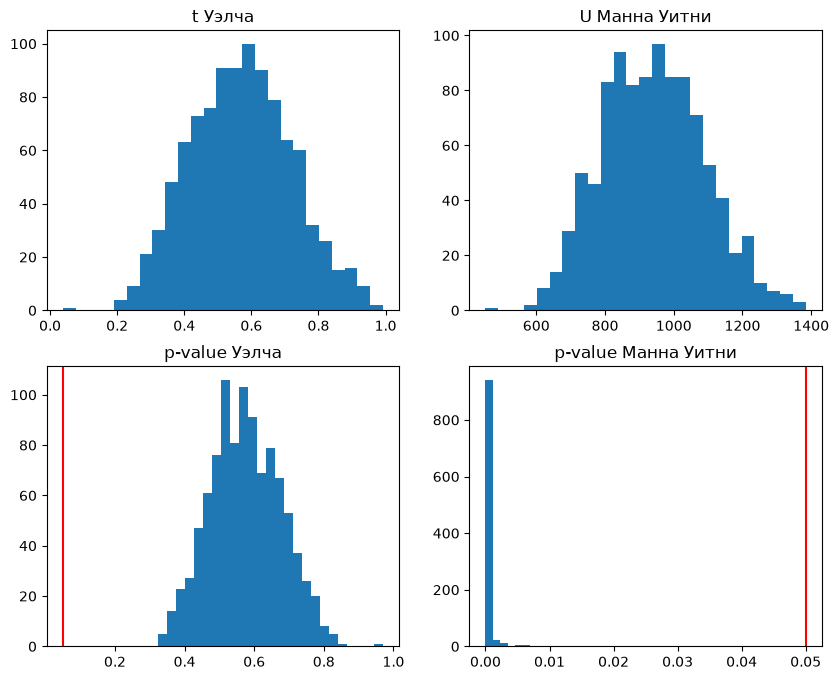

In [17]:
def _():
    rng = np.random.default_rng(7)

    diffs = []
    t_vals = []
    t_pvals = []
    u_vals = []
    u_pvals = []

    for _ in range(1000):
        g1 = rng.normal(0, 1, 60)
        g2 = rng.normal(1, 1, 60)
        
        # заменяем два наблюдения
        g2[0] = -50
        g2[1] = -50
        
        diffs.append(g2.mean() - g1.mean())
        
        res_t = stats.ttest_ind(g1, g2, equal_var=False)
        t_vals.append(res_t.statistic)
        t_pvals.append(res_t.pvalue)
        
        res_u = stats.mannwhitneyu(g1, g2)
        u_vals.append(res_u.statistic)
        u_pvals.append(res_u.pvalue)

    fig, ax = plt.subplots(2, 2, figsize=(10, 8))

    ax[0, 0].hist(t_vals, bins=25)
    ax[0, 0].set_title("t Уэлча")

    ax[0, 1].hist(u_vals, bins=25)
    ax[0, 1].set_title("U Манна Уитни")

    ax[1, 0].hist(t_pvals, bins=25)
    ax[1, 0].axvline(0.05, color="red")
    ax[1, 0].set_title("p-value Уэлча")

    ax[1, 1].hist(u_pvals, bins=25)
    ax[1, 1].axvline(0.05, color="red")
    ax[1, 1].set_title("p-value Манна Уитни")

    plt.show()

_()

На графиках видно, что у критерия Уэлча значения p-value сосредоточены справа от отметки 0.05 (в основном больше 0.3), а у критерия Манна-Уитни почти все значения лежат у нуля, левее линии 0.05. При двустороннем пороге 5% критерий Уэлча практически ни в одном из 1000 повторов не отвергает H0, а критерий Манна-Уитни, наоборот, почти во всех повторах отвергает H0. Выводы критериев полностью разошлись. Это произошло потому, что критерий Уэлча опирается на среднее и стандартное отклонение, а два выброса по -50 сильно сдвинули среднее второй группы вниз и раздули ее разброс, из-за чего тест перестал замечать эффект. Критерий Манна-Уитни переводит наблюдения в ранги, поэтому два выброса просто получили два самых маленьких ранга и почти не помешали увидеть, что остальные значения во второй группе больше, чем в первой.

## 6
6. Один раз наберите первую группу из N (10, 2), n1 = 80, и вторую из N (10,8, 2,6),
n2 = 75. Посчитайте 95% доверительный интервал Уэлча для разницы
средних «вторая минус первая» и p-value критерия Уэлча. Решите, есть ли
основание отвергать H0 при двустороннем пороге 5%. Напишите, попадает ли
0 в интервал и какой самый маленький эффект еще согласуется с данными (не
отвергает H0).

In [14]:
def _():
    rng = np.random.default_rng(7)

    g1 = rng.normal(10, 2, 80)
    g2 = rng.normal(10.8, 2.6, 75)

    # вторая группа минус первая
    diff = g2.mean() - g1.mean()

    res = stats.ttest_ind(g2, g1, equal_var=False)
    ci = res.confidence_interval(confidence_level=0.95)

    print(f"разница средних: {diff:.3f}")
    print(f"95% ДИ: от {ci.low:.3f} до {ci.high:.3f}")
    print(f"p-value: {res.pvalue:.3f}")

_()

разница средних: 0.757
95% ДИ: от 0.109 до 1.404
p-value: 0.022


Разница средних (вторая группа минус первая) получилась 0.757, 95% доверительный интервал от 0.109 до 1.404, а p-value равно 0.022. Основание отвергать H0 при двустороннем пороге 5% есть, так как p-value меньше 0.05, а ноль в доверительный интервал не попадает. Самый маленький эффект, который еще согласуется с данными и не отвергает H0, равен нижней границе интервала, то есть 0.109.

## 7
7. Возьмите те же две группы, что в предыдущей задаче. 2000 раз заново
соберите выборки того же размера: каждый раз берите наблюдения из уже
полученных групп с возвращением (в numpy для этого есть rng.choice с
параметром replace=True) и заново считайте разницу средних. Нарисуйте
распределение этих разниц. 95% интервал бутстрапа — границы, отсекающие
по 2,5% значений с каждого края. Сравните эти границы с интервалом из
предыдущей задачи. Отдельно посчитайте, в какой доле таких повторных
выборок разница получилась не больше нуля. Можно ли эту долю назвать
p-value? Объясните.

95% ДИ бутстрапа: от 0.111 до 1.403
доля выборок <= 0: 0.009


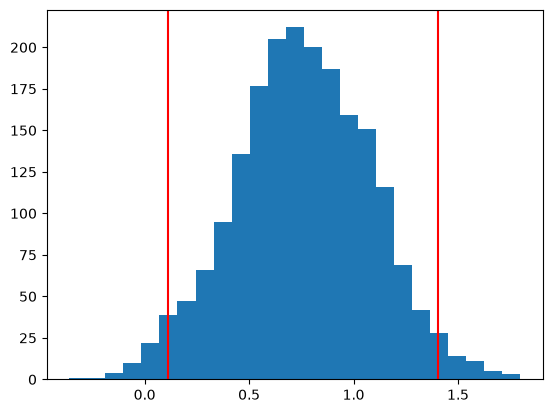

In [ ]:
def _():
    rng = np.random.default_rng(7)

    g1 = rng.normal(10, 2, 80)
    g2 = rng.normal(10.8, 2.6, 75)

    diffs = []

    for _ in range(2000):
        b1 = rng.choice(g1, size=80, replace=True)
        b2 = rng.choice(g2, size=75, replace=True)
        diffs.append(b2.mean() - b1.mean())

    diffs = np.array(diffs)

    ci_low = np.percentile(diffs, 2.5)
    ci_high = np.percentile(diffs, 97.5)

    # доля где разница не больше нуля
    share = np.mean(diffs <= 0)

    print(f"95% ДИ бутстрапа: от {ci_low:.3f} до {ci_high:.3f}")
    print(f"доля выборок <= 0: {share:.3f}")

    plt.hist(diffs, bins=25)
    plt.axvline(ci_low, color="red")
    plt.axvline(ci_high, color="red")
    plt.show()

_()

Границы доверительного интервала в бутстрапе получились от 0.111 до 1.403. Они почти совпали с интервалом Уэлча из прошлой задачи (от 0.109 до 1.404), в бутстрапе интервал вышел совсем чуть-чуть уже. Доля повторных выборок, где разница оказалась не больше нуля, равна 0.009. Назвать эту долю p-value нельзя, потому что p-value по определению считается при условии, что верна H0 (то есть распределение должно быть построено вокруг нуля, когда реальной разницы между группами нет). Здесь же распределение построено вокруг нашей выборочной разницы 0.757, плюс мы посчитали только один левый хвост от нуля, а не оба хвоста, как при двусторонней проверке.